[**********************60%****                   ]  3 of 5 completed

[*********************100%***********************]  5 of 5 completed



Estimated parameters:
Drift:
 Ticker
AAPL    0.000983
GC=F    0.000434
GOOG    0.000818
MSFT    0.000803
TSLA    0.002104
dtype: float64

Growth:
 Ticker
AAPL    0.000981
GC=F    0.000433
GOOG    0.000816
MSFT    0.000801
TSLA    0.002099
dtype: float64

Volatility:
 Ticker
AAPL    0.019940
GC=F    0.010258
GOOG    0.020417
MSFT    0.019228
TSLA    0.042205
dtype: float64

Processing AAPL...


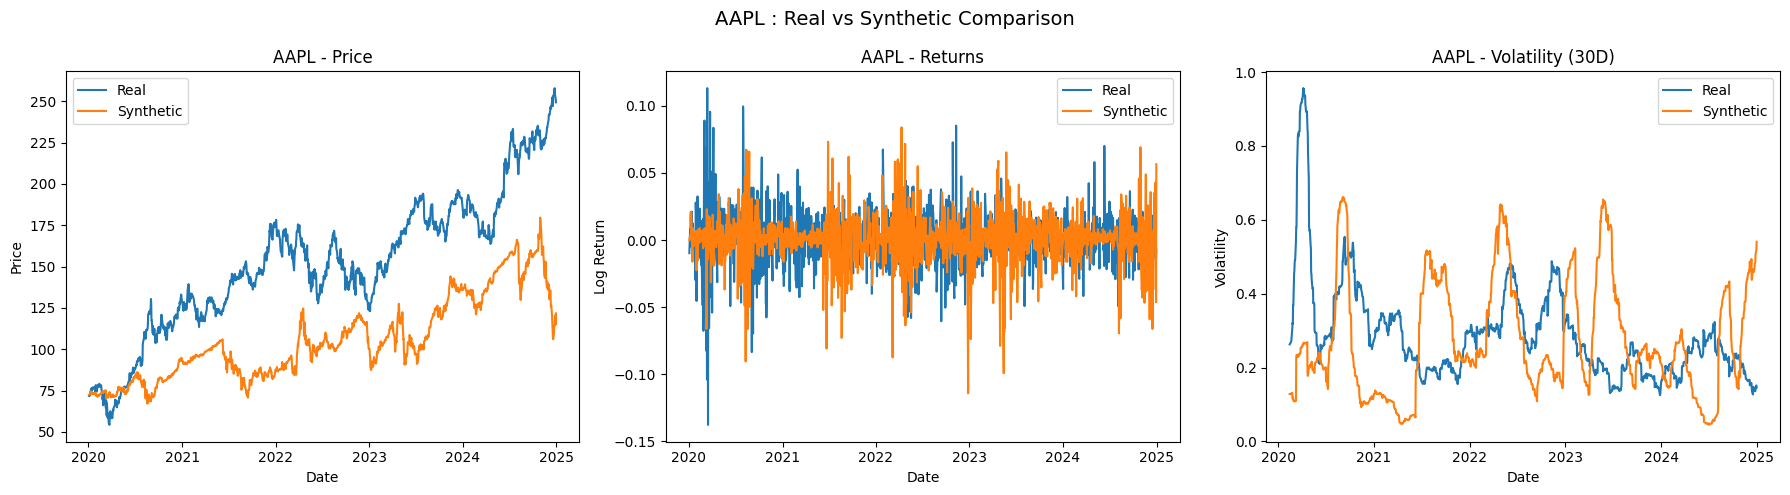


Processing MSFT...


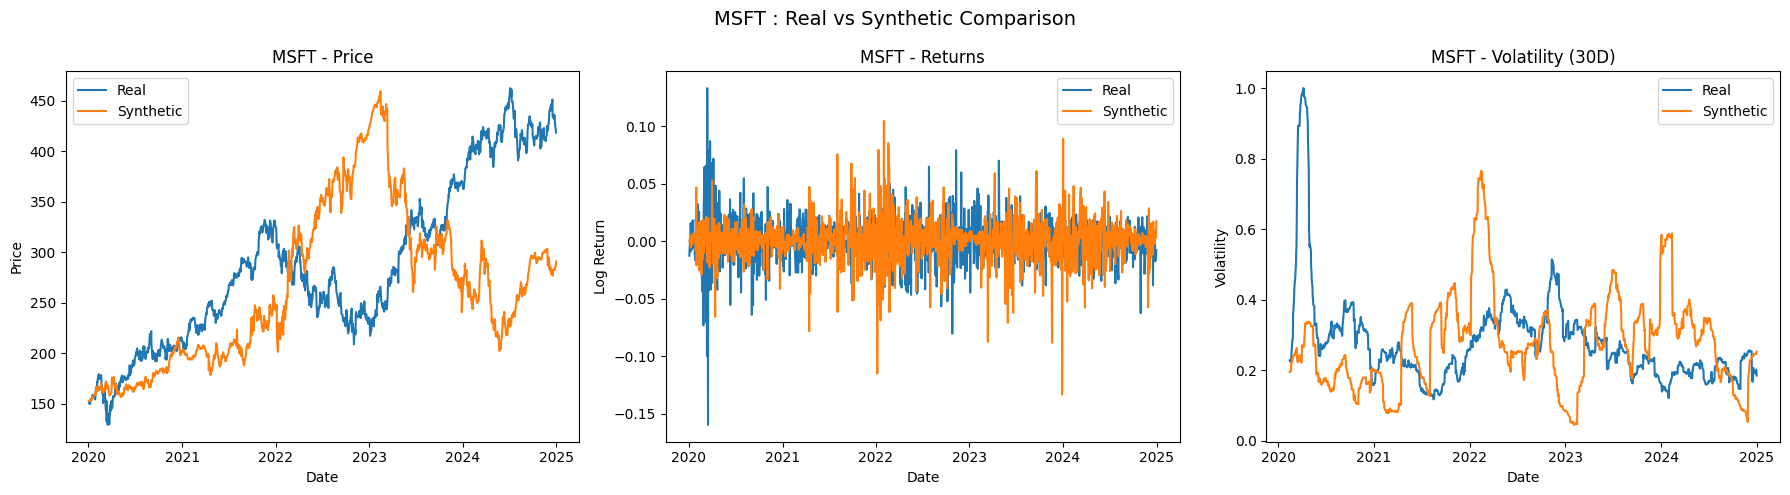


Processing GOOG...


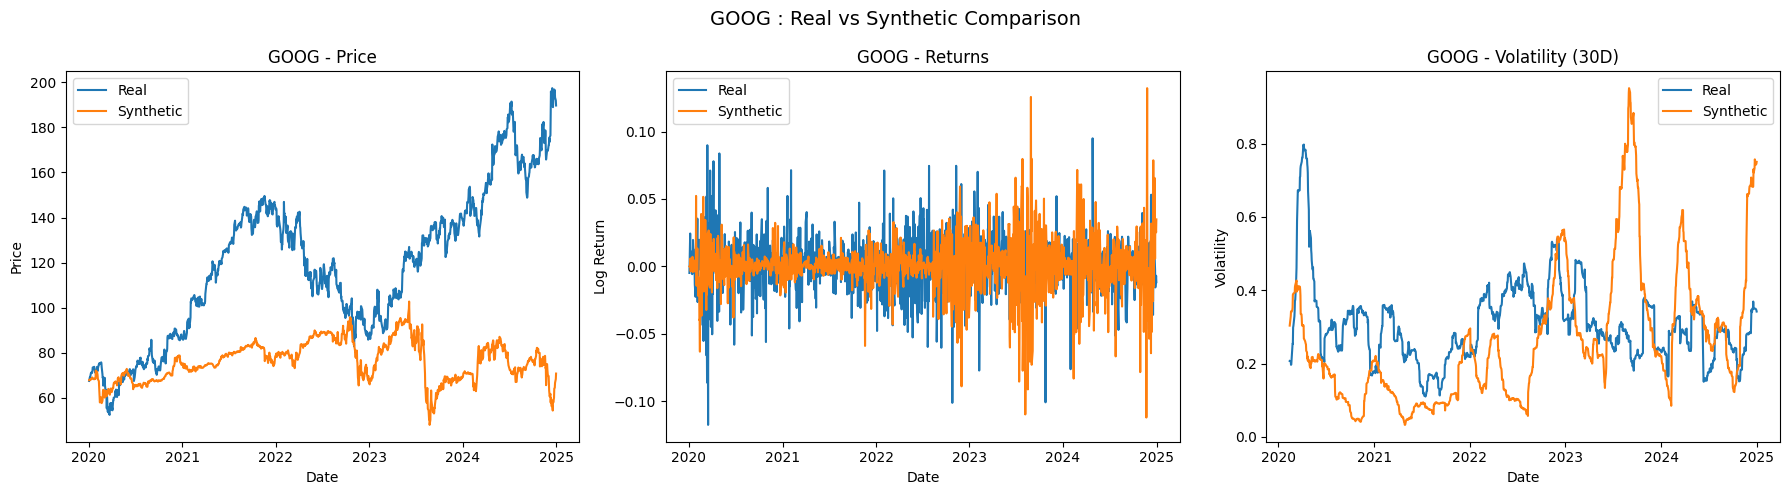


Processing TSLA...


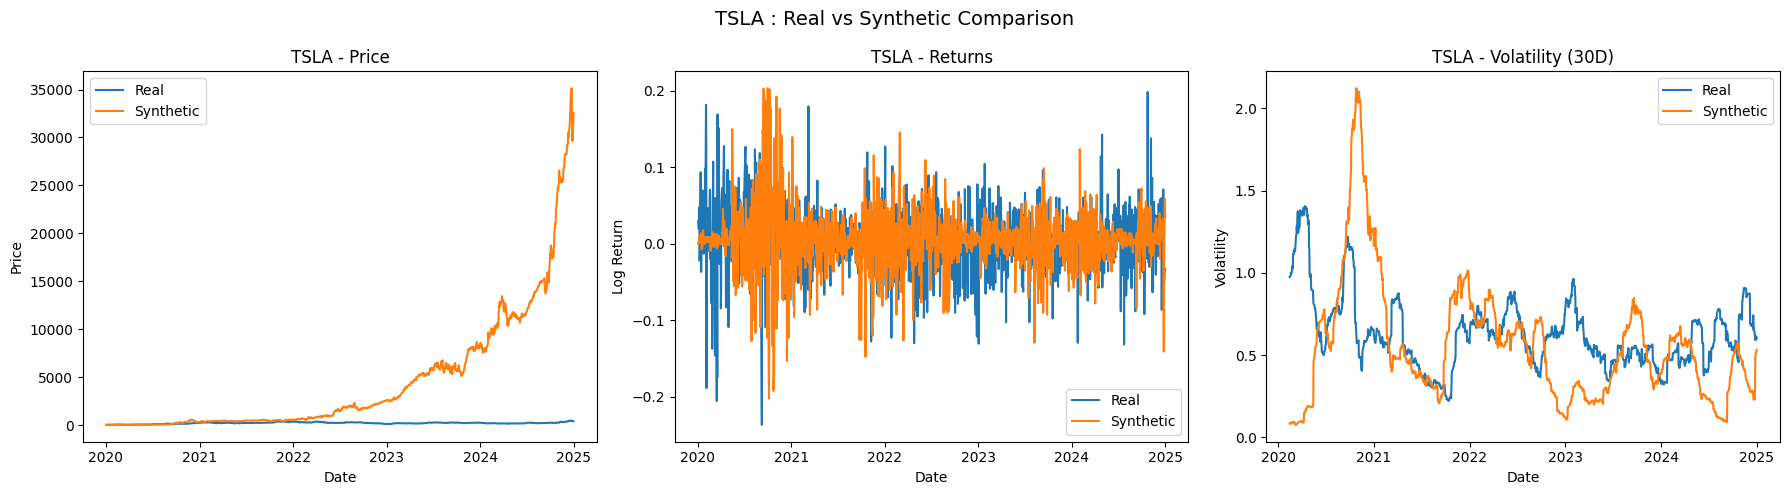


Processing GC=F...


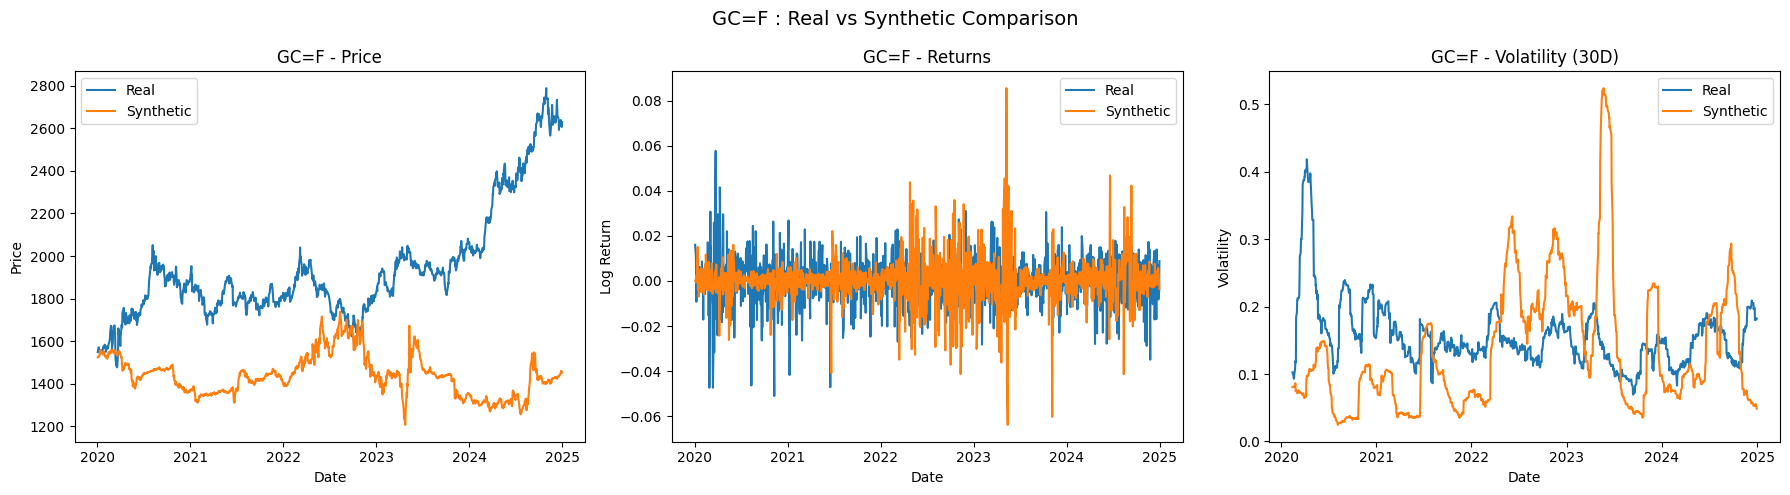


Done.


In [13]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


# =====================================================
# Settings
# =====================================================

np.random.seed(42)

stocks = ["AAPL", "MSFT", "GOOG", "TSLA", "GC=F"]
start = "2020-01-01"
end = "2025-01-01"

# GARCH base params (will be scaled by data)
phi = 0.05
omega = 1e-6
alpha = 0.12
beta = 0.85


# Jump parameters (for peaks/crashes)
JUMP_LAMBDA = 0.04     # frequency
JUMP_MU = -0.02        # average jump (slightly negative)
JUMP_SIGMA = 0.05


# =====================================================
# Download Real Data
# =====================================================

print("Downloading data...")

data = yf.download(
    stocks,
    start=start,
    end=end,
    auto_adjust=True
)["Close"]

data = data.dropna()


# =====================================================
# Compute Real Returns
# =====================================================

real_log_returns = np.log(data / data.shift(1)).dropna()

# Daily drift
drift_est = real_log_returns.mean()

# Volatility
vol_est = real_log_returns.std()


# =====================================================
# Structural Growth (CAGR)
# =====================================================

years = (data.index[-1] - data.index[0]).days / 365

cagr = (data.iloc[-1] / data.iloc[0])**(1/years) - 1

daily_growth = np.log(1 + cagr) / 252


print("\nEstimated parameters:")
print("Drift:\n", drift_est)
print("\nGrowth:\n", daily_growth)
print("\nVolatility:\n", vol_est)


# =====================================================
# GARCH + Jump + Growth Generator
# =====================================================

def generate_market_returns(
    T,
    mu,
    growth,
    phi,
    omega,
    alpha,
    beta,
    jump_lambda,
    jump_mu,
    jump_sigma
):

    r = np.zeros(T)
    eps = np.zeros(T)
    sigma2 = np.zeros(T)

    # Initial variance
    sigma2[0] = omega / (1 - alpha - beta)

    for t in range(1, T):

        # GARCH variance
        sigma2[t] = (
            omega
            + alpha * eps[t-1]**2
            + beta * sigma2[t-1]
        )

        # Base shock
        z = np.random.normal()
        base = np.sqrt(sigma2[t]) * z

        # Jump
        jump = 0

        if np.random.rand() < jump_lambda:

            jump = np.random.normal(
                jump_mu,
                jump_sigma
            )

            # Drift compensation
            jump -= jump_lambda * jump_mu


        # Total shock
        eps[t] = base + jump

        # Return with growth
        r[t] = growth + mu + phi * r[t-1] + eps[t]

    return r


# =====================================================
# Main Loop
# =====================================================

for stock in stocks:

    print(f"\nProcessing {stock}...")

    # -----------------------
    # Real Data
    # -----------------------

    real_prices = data[stock].dropna()

    real_returns = np.log(
        real_prices / real_prices.shift(1)
    ).dropna()

    real_vol = real_returns.rolling(30).std() * np.sqrt(252)


    # -----------------------
    # Parameters (per stock)
    # -----------------------

    mu = drift_est[stock]
    growth = daily_growth[stock]

    T = len(real_returns)


    # -----------------------
    # Synthetic Returns
    # -----------------------

    syn_returns = generate_market_returns(
        T=T,
        mu=mu,
        growth=growth,
        phi=phi,
        omega=omega,
        alpha=alpha,
        beta=beta,
        jump_lambda=JUMP_LAMBDA,
        jump_mu=JUMP_MU,
        jump_sigma=JUMP_SIGMA
    )

    syn_returns = pd.Series(
        syn_returns,
        index=real_returns.index
    )


    # -----------------------
    # Match Volatility Scale
    # -----------------------

    syn_returns *= real_returns.std() / syn_returns.std()


    # -----------------------
    # Synthetic Prices
    # -----------------------

    S0 = real_prices.iloc[0]

    syn_prices = S0 * np.exp(
        syn_returns.cumsum()
    )

    syn_prices = pd.Series(
        syn_prices,
        index=real_returns.index
    )


    syn_vol = syn_returns.rolling(30).std() * np.sqrt(252)


    # =================================================
    # PLOTS
    # =================================================

    # =================================================
    # SIDE-BY-SIDE PLOTS
    # =================================================

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # -------- Prices --------
    axes[0].plot(
        real_prices.loc[syn_prices.index],
        label="Real"
    )
    axes[0].plot(
        syn_prices,
        label="Synthetic"
    )

    axes[0].set_title(f"{stock} - Price")
    axes[0].set_xlabel("Date")
    axes[0].set_ylabel("Price")
    axes[0].legend()


    # -------- Returns --------
    axes[1].plot(real_returns, label="Real")
    axes[1].plot(syn_returns, label="Synthetic")

    axes[1].set_title(f"{stock} - Returns")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("Log Return")
    axes[1].legend()


    # -------- Volatility --------
    axes[2].plot(real_vol, label="Real")
    axes[2].plot(syn_vol, label="Synthetic")

    axes[2].set_title(f"{stock} - Volatility (30D)")
    axes[2].set_xlabel("Date")
    axes[2].set_ylabel("Volatility")
    axes[2].legend()


    plt.suptitle(f"{stock} : Real vs Synthetic Comparison", fontsize=14)

    plt.tight_layout()
    plt.show()

print("\nDone.")


[*********************100%***********************]  5 of 5 completed


Estimated parameters:
Drift:
 Ticker
AAPL    0.000983
GC=F    0.000434
GOOG    0.000818
MSFT    0.000803
TSLA    0.002104
dtype: float64

Growth:
 Ticker
AAPL    0.000981
GC=F    0.000433
GOOG    0.000816
MSFT    0.000801
TSLA    0.002099
dtype: float64

Volatility:
 Ticker
AAPL    0.019940
GC=F    0.010258
GOOG    0.020417
MSFT    0.019228
TSLA    0.042205
dtype: float64

Processing AAPL...


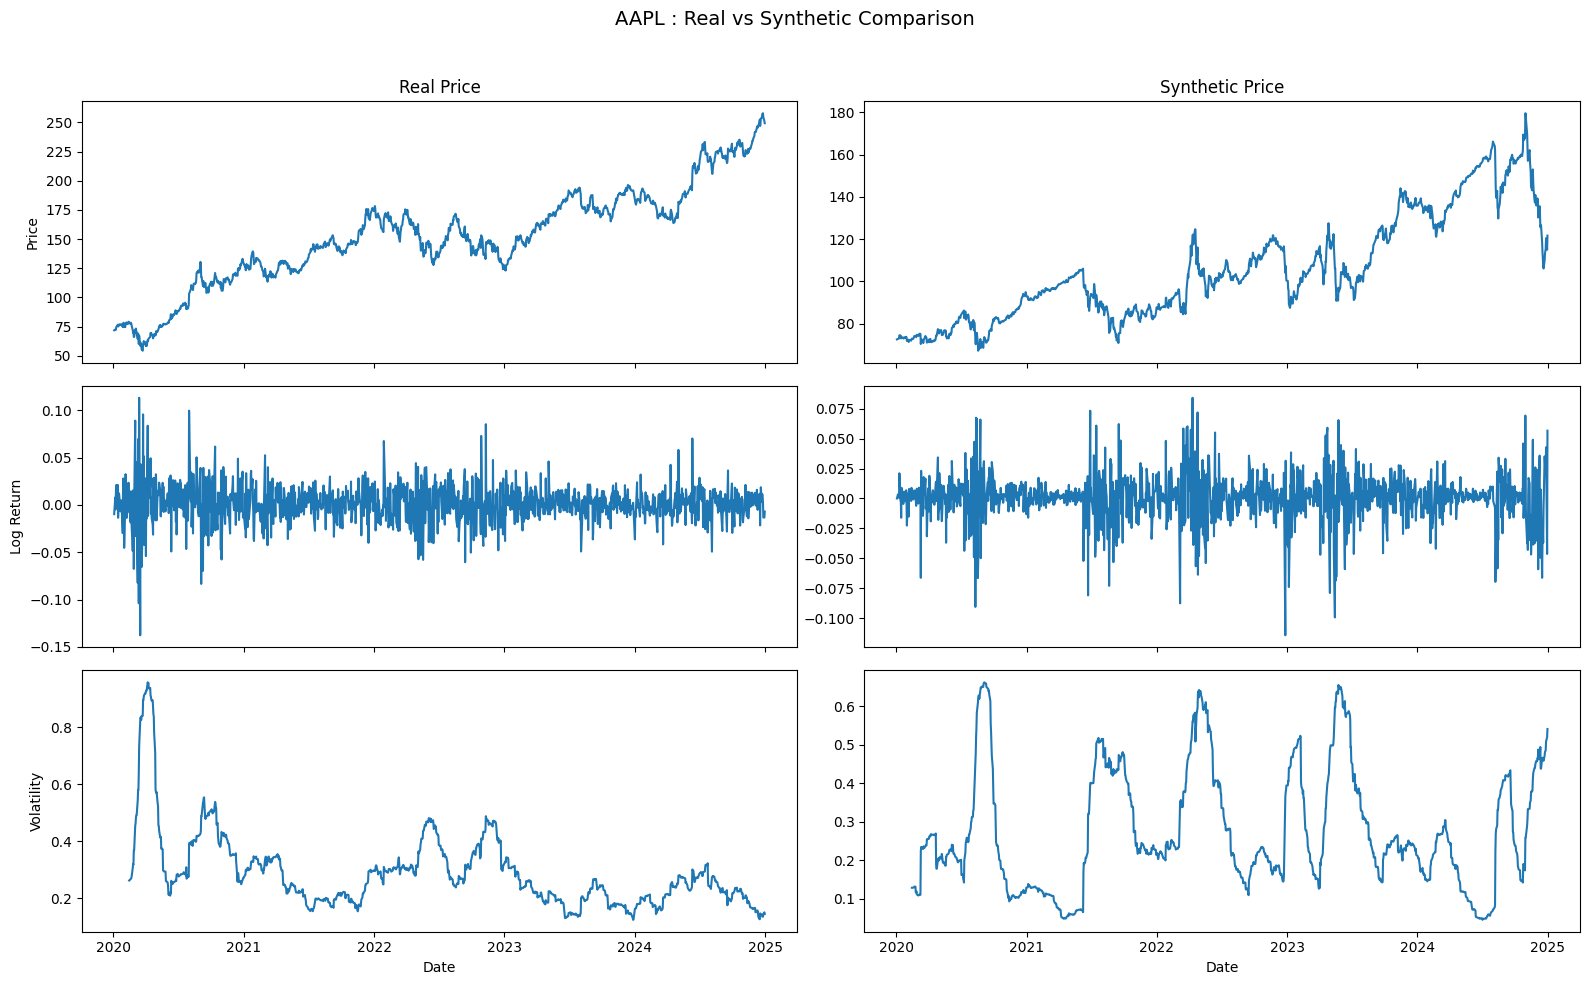


Processing MSFT...


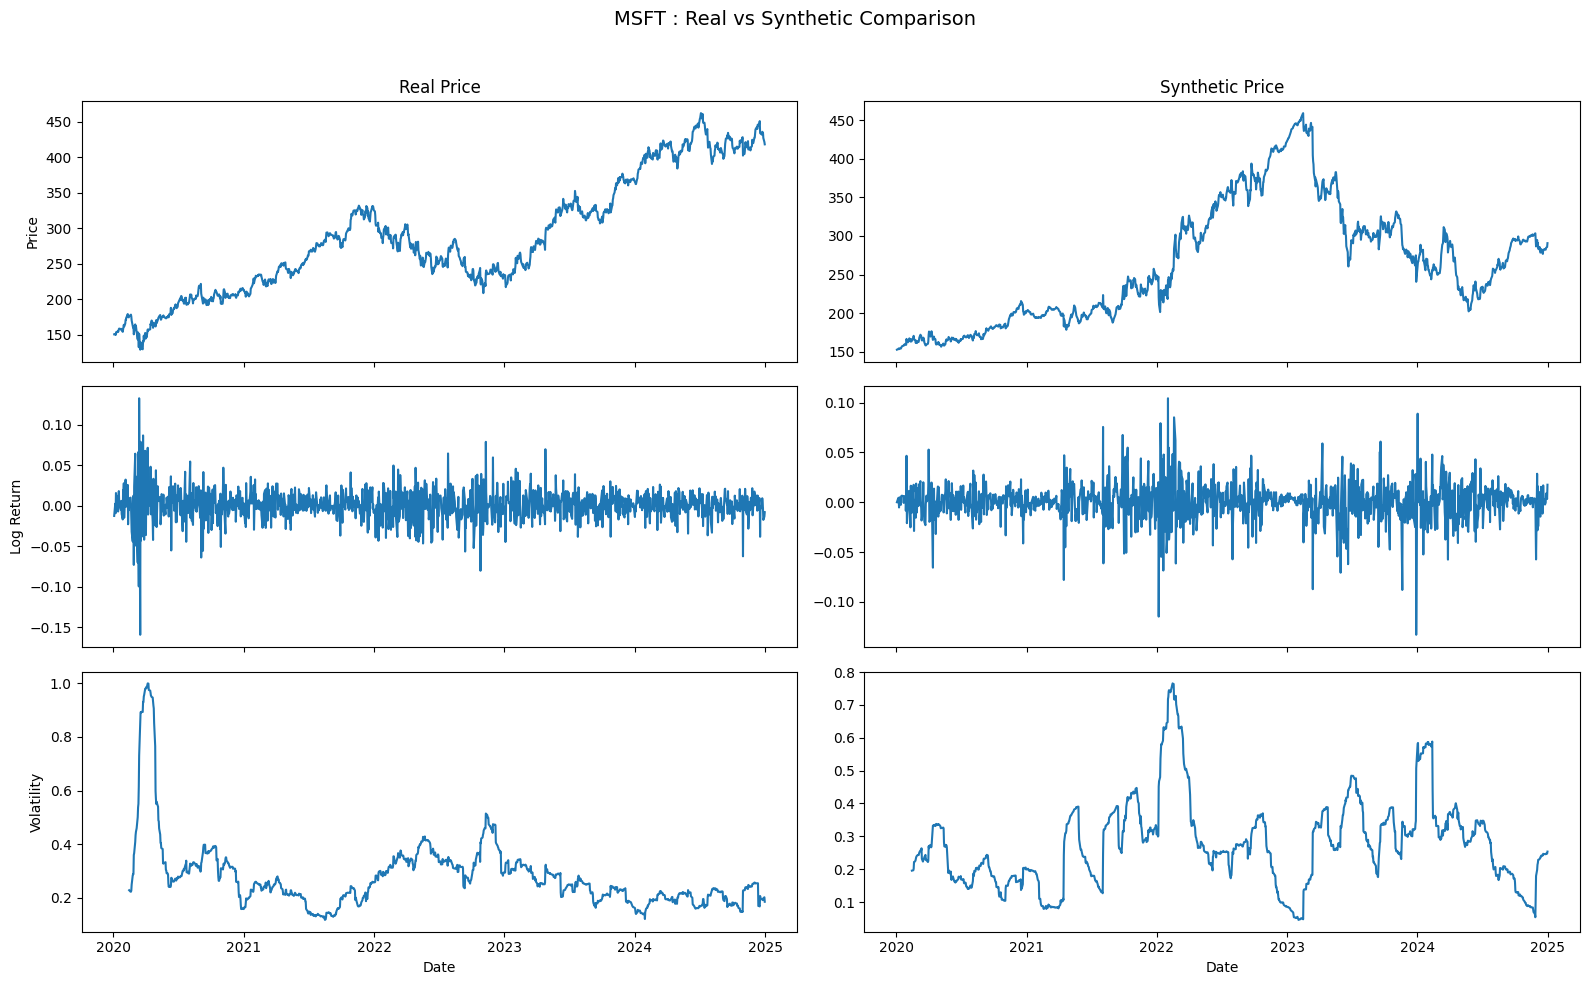


Processing GOOG...


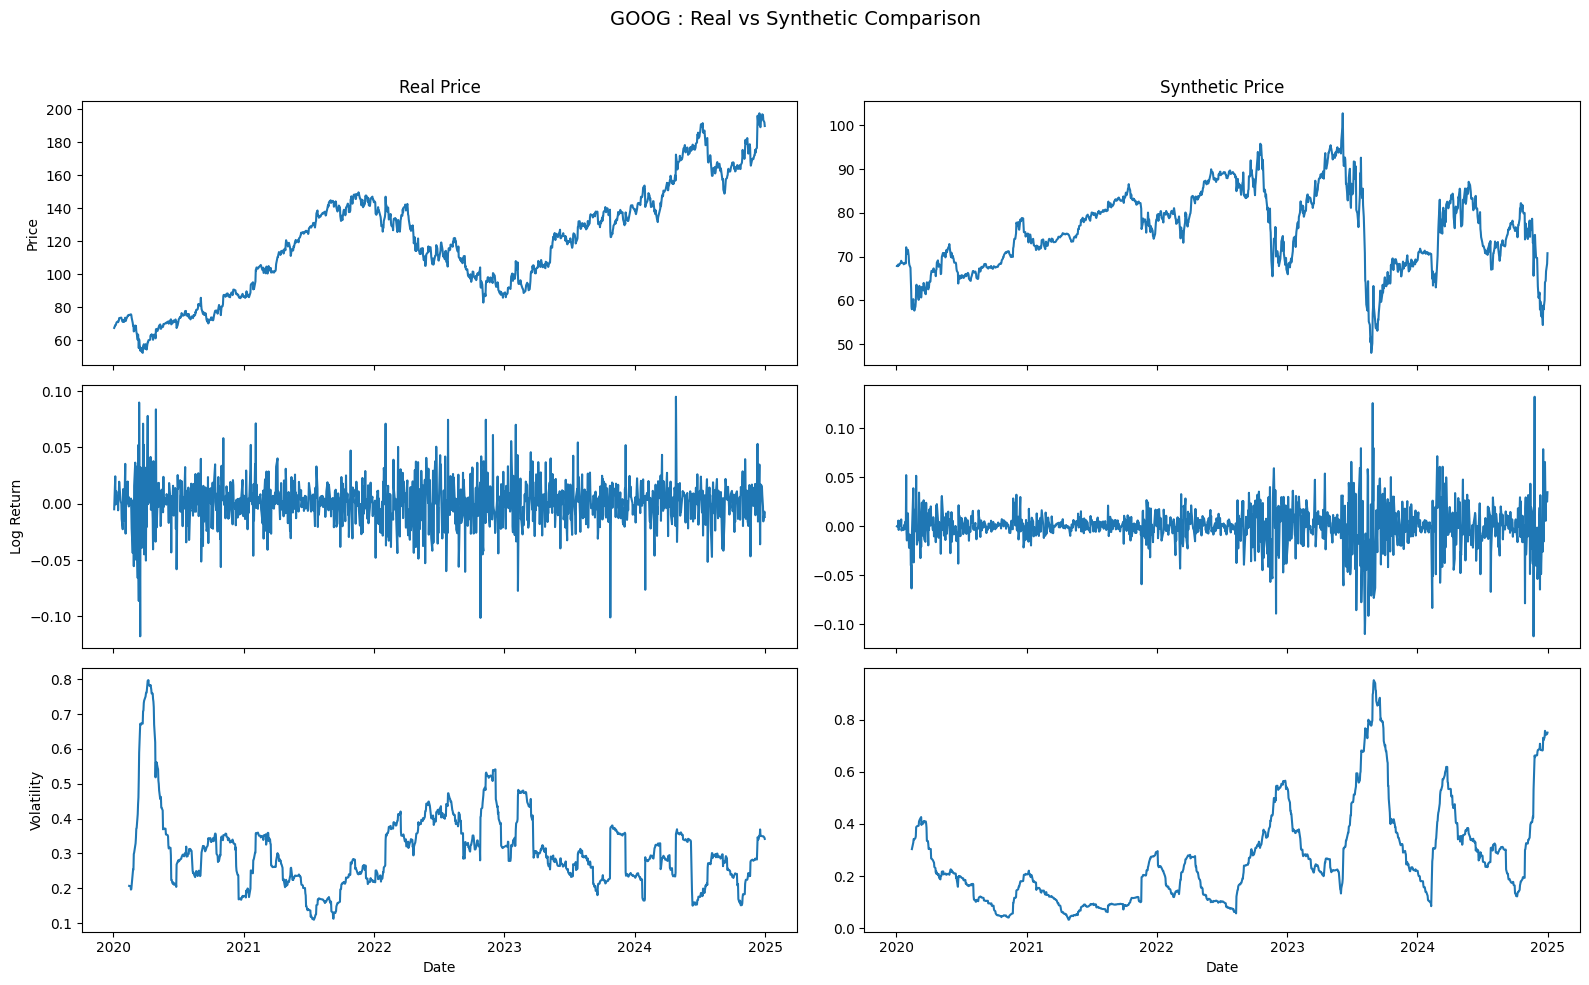


Processing TSLA...


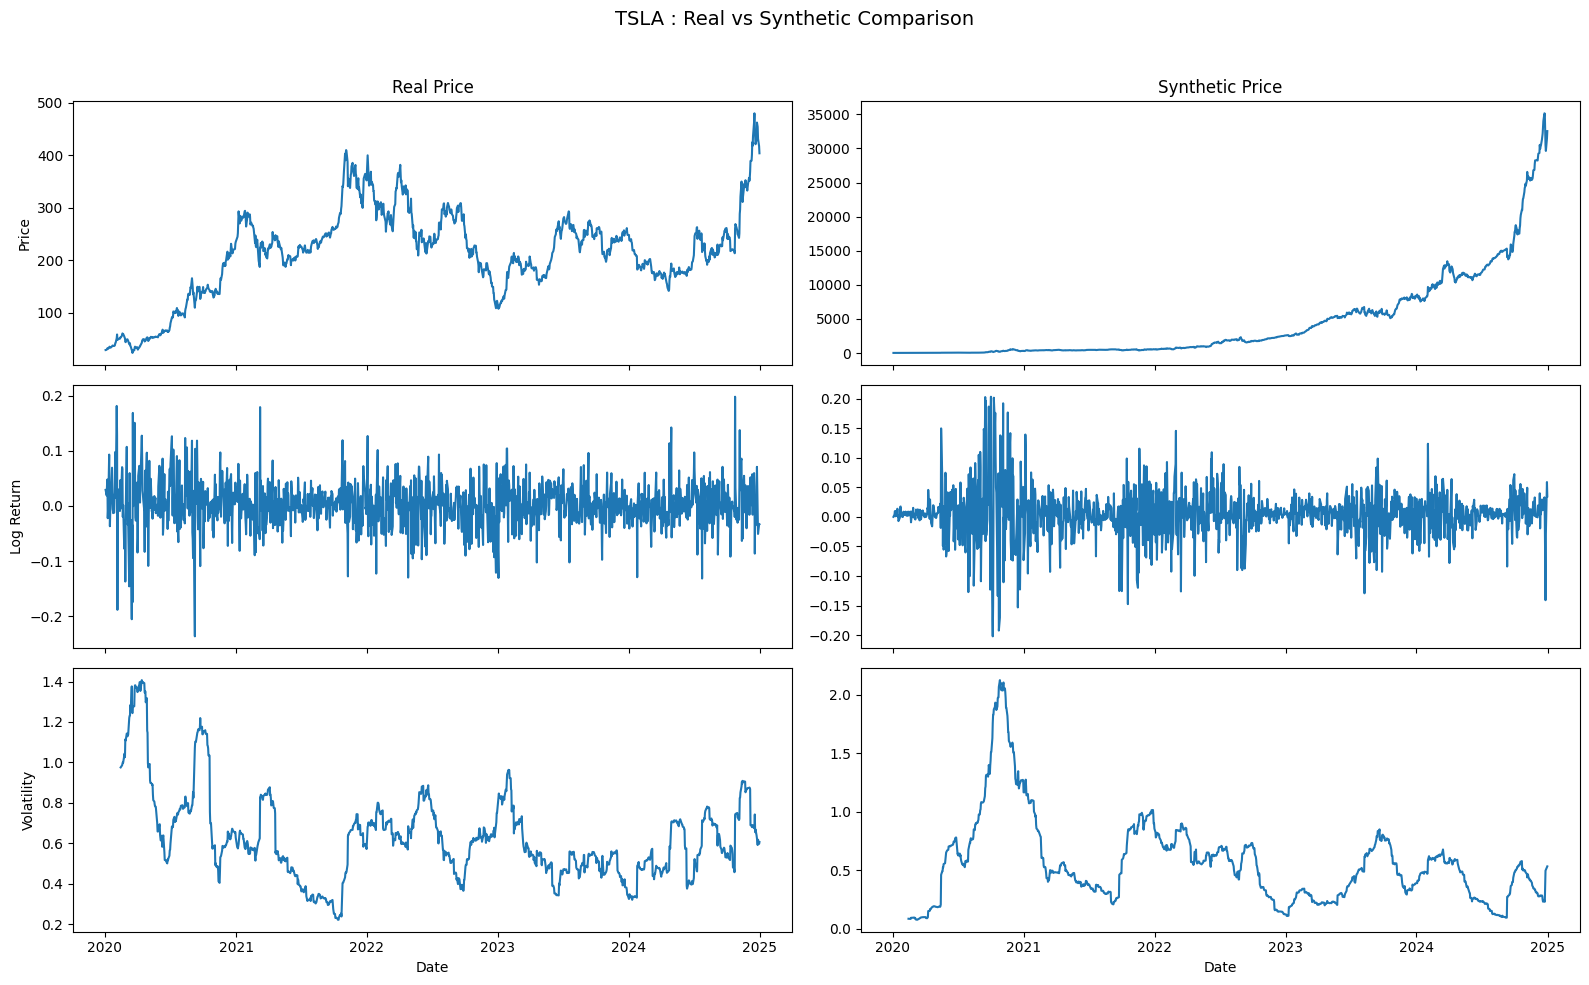


Processing GC=F...


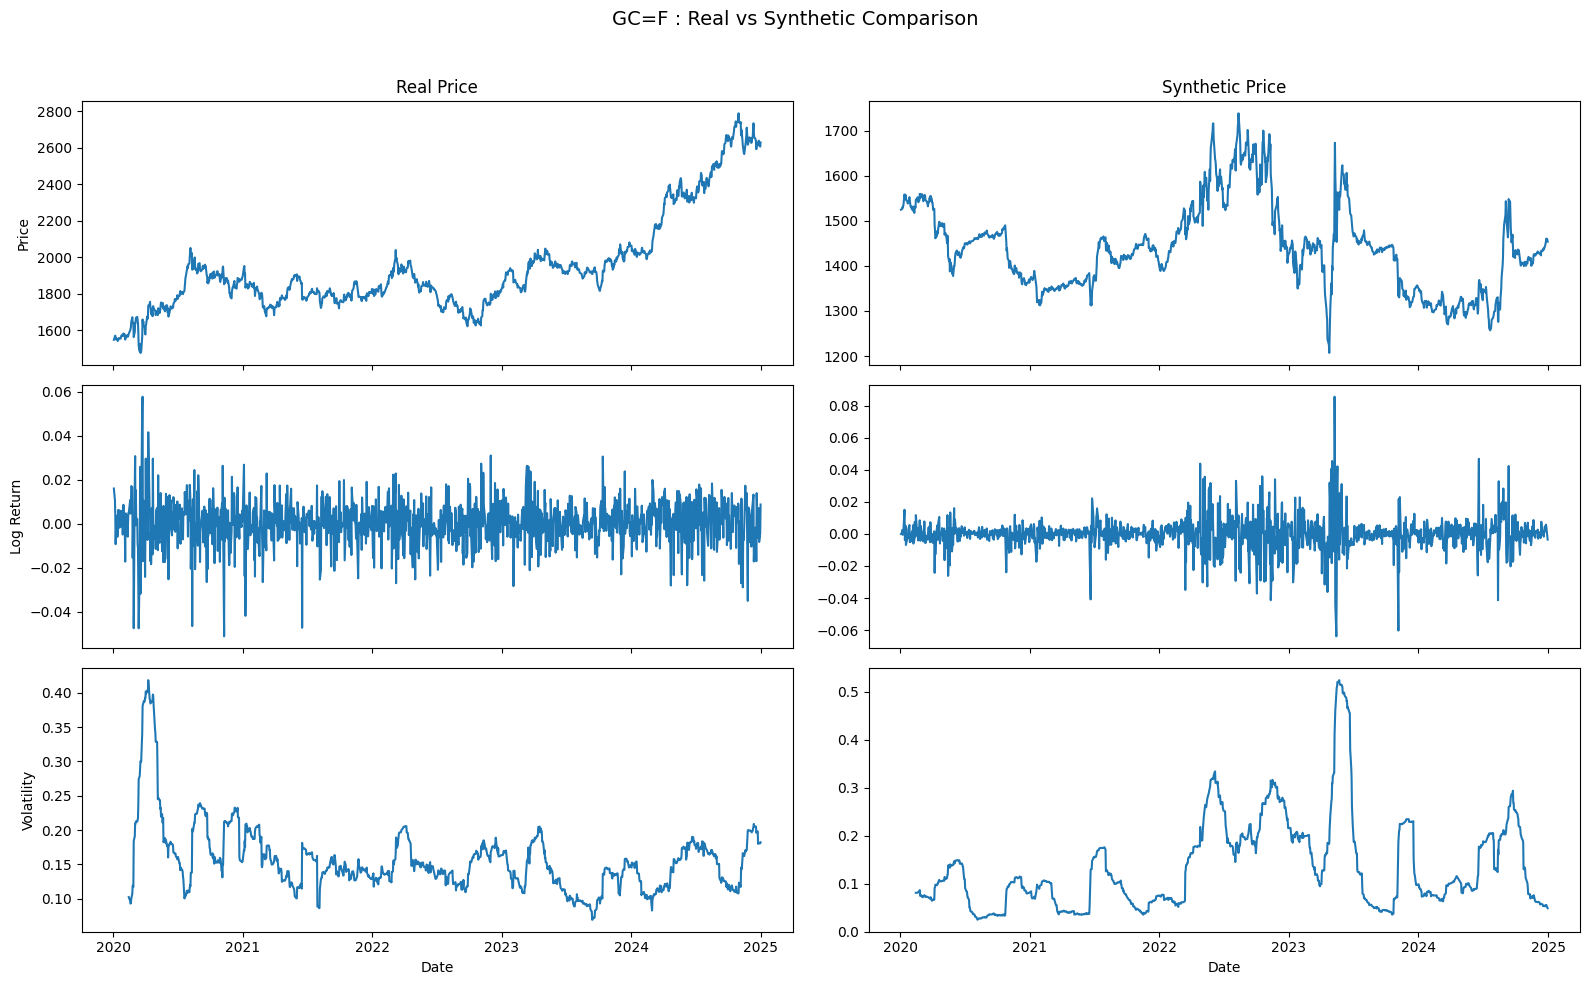


Done.


In [14]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt


# =====================================================
# Settings
# =====================================================

np.random.seed(42)

stocks = ["AAPL", "MSFT", "GOOG", "TSLA","GC=F"]
start = "2020-01-01"
end = "2025-01-01"

# GARCH base params (will be scaled by data)
phi = 0.05
omega = 1e-6
alpha = 0.12
beta = 0.85


# Jump parameters (for peaks/crashes)
JUMP_LAMBDA = 0.04     # frequency
JUMP_MU = -0.02        # average jump (slightly negative)
JUMP_SIGMA = 0.05


# =====================================================
# Download Real Data
# =====================================================

print("Downloading data...")

data = yf.download(
    stocks,
    start=start,
    end=end,
    auto_adjust=True
)["Close"]

data = data.dropna()


# =====================================================
# Compute Real Returns
# =====================================================

real_log_returns = np.log(data / data.shift(1)).dropna()

# Daily drift
drift_est = real_log_returns.mean()

# Volatility
vol_est = real_log_returns.std()


# =====================================================
# Structural Growth (CAGR)
# =====================================================

years = (data.index[-1] - data.index[0]).days / 365

cagr = (data.iloc[-1] / data.iloc[0])**(1/years) - 1

daily_growth = np.log(1 + cagr) / 252


print("\nEstimated parameters:")
print("Drift:\n", drift_est)
print("\nGrowth:\n", daily_growth)
print("\nVolatility:\n", vol_est)


# =====================================================
# GARCH + Jump + Growth Generator
# =====================================================

def generate_market_returns(
    T,
    mu,
    growth,
    phi,
    omega,
    alpha,
    beta,
    jump_lambda,
    jump_mu,
    jump_sigma
):

    r = np.zeros(T)
    eps = np.zeros(T)
    sigma2 = np.zeros(T)

    # Initial variance
    sigma2[0] = omega / (1 - alpha - beta)

    for t in range(1, T):

        # GARCH variance
        sigma2[t] = (
            omega
            + alpha * eps[t-1]**2
            + beta * sigma2[t-1]
        )

        # Base shock
        z = np.random.normal()
        base = np.sqrt(sigma2[t]) * z

        # Jump
        jump = 0

        if np.random.rand() < jump_lambda:

            jump = np.random.normal(
                jump_mu,
                jump_sigma
            )

            # Drift compensation
            jump -= jump_lambda * jump_mu


        # Total shock
        eps[t] = base + jump

        # Return with growth
        r[t] = growth + mu + phi * r[t-1] + eps[t]

    return r


# =====================================================
# Main Loop
# =====================================================

for stock in stocks:

    print(f"\nProcessing {stock}...")

    # -----------------------
    # Real Data
    # -----------------------

    real_prices = data[stock].dropna()

    real_returns = np.log(
        real_prices / real_prices.shift(1)
    ).dropna()

    real_vol = real_returns.rolling(30).std() * np.sqrt(252)


    # -----------------------
    # Parameters (per stock)
    # -----------------------

    mu = drift_est[stock]
    growth = daily_growth[stock]

    T = len(real_returns)


    # -----------------------
    # Synthetic Returns
    # -----------------------

    syn_returns = generate_market_returns(
        T=T,
        mu=mu,
        growth=growth,
        phi=phi,
        omega=omega,
        alpha=alpha,
        beta=beta,
        jump_lambda=JUMP_LAMBDA,
        jump_mu=JUMP_MU,
        jump_sigma=JUMP_SIGMA
    )

    syn_returns = pd.Series(
        syn_returns,
        index=real_returns.index
    )


    # -----------------------
    # Match Volatility Scale
    # -----------------------

    syn_returns *= real_returns.std() / syn_returns.std()


    # -----------------------
    # Synthetic Prices
    # -----------------------

    S0 = real_prices.iloc[0]

    syn_prices = S0 * np.exp(
        syn_returns.cumsum()
    )

    syn_prices = pd.Series(
        syn_prices,
        index=real_returns.index
    )


    syn_vol = syn_returns.rolling(30).std() * np.sqrt(252)


    # =================================================
    # PLOTS
    # =================================================

    # =================================================
    # SIDE-BY-SIDE PLOTS
    # =================================================

    # =================================================
    # REAL vs SYNTHETIC GRID
    # =================================================

    fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)


    # ------------------ PRICE ------------------

    # Real
    axes[0, 0].plot(real_prices.loc[syn_prices.index])
    axes[0, 0].set_title("Real Price")
    axes[0, 0].set_ylabel("Price")

    # Synthetic
    axes[0, 1].plot(syn_prices)
    axes[0, 1].set_title("Synthetic Price")


    # ------------------ RETURNS ------------------

    # Real
    axes[1, 0].plot(real_returns)
    axes[1, 0].set_ylabel("Log Return")

    # Synthetic
    axes[1, 1].plot(syn_returns)


    # ------------------ VOLATILITY ------------------

    # Real
    axes[2, 0].plot(real_vol)
    axes[2, 0].set_ylabel("Volatility")

    # Synthetic
    axes[2, 1].plot(syn_vol)


    # ------------------ Formatting ------------------

    axes[2, 0].set_xlabel("Date")
    axes[2, 1].set_xlabel("Date")

    plt.suptitle(f"{stock} : Real vs Synthetic Comparison", fontsize=14)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


print("\nDone.")
